# Etapa 2 - Limpieza y transformación de datos
**Proyecto 2: Analítica de Airbnb en San Francisco**

 Ingeniería de datos



In [51]:
import json

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

## 1. Cargamos los Datos

In [52]:
df = pd.read_csv("datos\listings.csv")
filas_iniciales, columnas_iniciales = df.shape
df.shape

<>:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\User\AppData\Local\Temp\ipykernel_20116\3128704914.py:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  df = pd.read_csv("datos\listings.csv")


(7405, 90)

In [53]:
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,41789520,https://www.airbnb.com/rooms/41789520,20260914002145,2026-09-14,NaN,Private room with private bathroom in Castro c...,Come stay in my home in the vibrant Castro nie...,NaN,https://a0.muscache.com/pictures/f37e8054-bf2a...,14765200,https://www.airbnb.com/users/show/14765200,1462946378881272192,https://www.airbnb.com/users/profile/146294637...,Mishi,NaN,12,4,12,3,"San Francisco, CA",I'm a San Francisco native working in the wine...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/80bf4...,NaN,1,NaN,NaN,t,t,NaN,Castro/Upper Market,NaN,37.761730,-122.436040,Private room in condo,Private room,2,NaN,1 private bath,1.0,2.0,"[""Clothing storage"", ""Hot water"", ""Garden view...",$195.50,2026-10-02,2026-10-04,391.00,195.50,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",2.0,30.0,2.0,2.0,30.0,30.0,2.0,30.0,NaN,t,5,27,54,329,2026-09-14,154,23,3,73,22,253,49462.0,2020-03-01,2026-08-28,4.9,4.89,4.82,4.94,4.95,4.92,4.83,STR-0004829,NaN,1,0,1,0,1.93
1,49838960,https://www.airbnb.com/rooms/49838960,20260914002145,2026-09-14,NaN,Twin Peaks Oasis,Completely redecorated Mid-Century Modern home...,NaN,https://a0.muscache.com/pictures/fc7024d0-9aba...,4430565,https://www.airbnb.com/users/show/4430565,1462657300271776589,https://www.airbnb.com/users/profile/146265730...,Jane,NaN,13,8,5,1,"San Francisco, CA",I'm from San Francisco and moved here in 1999 ...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/33463...,NaN,1,NaN,NaN,t,t,NaN,Twin Peaks,NaN,37.752270,-122.450730,Entire home,Entire home/apt,6,NaN,2 baths,3.0,3.0,"[""Pets allowed"", ""Cooking basics"", ""Hot water""...",$308.41,2027-02-17,2027-03-19,9252.18,308.41,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",30.0,1125.0,30.0,30.0,1125.0,1125.0,30.0,1125.0,NaN,t,11,14,16,174,2026-09-14,25,4,0,16,7,240,74018.0,2021-10-31,2026-07-14,5.0,5.00,4.88,5.00,5.00,4.92,4.84,NaN,NaN,1,1,0,0,0.42
2,1039800918426600713,https://www.airbnb.com/rooms/1039800918426600713,20260914002145,2026-09-14,previous scrape,"Mobility accessible, & The Line signature styling",Experience the vibrant SF culture at Turk and ...,NaN,https://a0.muscache.com/pictures/prohost-api/H...,544610857,https://www.airbnb.com/users/show/544610857,1470438888167888892,https://www.airbnb.com/users/profile/147043888...,"The Timbri, A Curio Collect

In [54]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7405 entries, 0 to 7404
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            7405 non-null   int64  
 1   listing_url                                   7405 non-null   str    
 2   scrape_id                                     7405 non-null   int64  
 3   last_scraped                                  7405 non-null   str    
 4   source                                        1682 non-null   str    
 5   name                                          7405 non-null   str    
 6   description                                   7394 non-null   str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   7405 non-null   str    
 9   host_id                                       7405 non-null   int64  
 10 

## 2. Columnas vacías


In [55]:
df.isnull().sum().sort_values(ascending=False).head(30)

neighborhood_overview           7405
host_since                      7405
host_response_time              7405
host_thumbnail_url              7405
host_acceptance_rate            7405
host_response_rate              7405
host_verifications              7405
neighbourhood                   7405
host_total_listings_count       7405
host_neighbourhood              7405
calendar_updated                7405
instant_bookable                7405
neighbourhood_group_cleansed    7405
bathrooms                       7405
source                          5723
host_about                      2883
license                         2599
host_location                   1751
price_quote_total_price         1714
price                           1714
price_quote_price_per_night     1714
estimated_revenue_l365d         1714
review_scores_checkin           1604
review_scores_location          1604
review_scores_value             1604
review_scores_accuracy          1603
review_scores_communication     1603
r

Hay columnas que están completamente vacías. No sirven, así que las eliminamos.

In [56]:
df = df.dropna(axis=1, how="all")
df.shape

(7405, 76)

## 3. Escoger las columnas que sirven
Miramos todas las columnas que quedan.

In [57]:
df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'picture_url', 'host_id', 'host_url', 'host_profile_id',
       'host_profile_url', 'host_name', 'hosts_time_as_user_years',
       'hosts_time_as_user_months', 'hosts_time_as_host_years',
       'hosts_time_as_host_months', 'host_location', 'host_about',
       'host_is_superhost', 'host_picture_url', 'host_listings_count',
       'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type',
       'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds',
       'amenities', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights',
       'minimum_maximum_nights', 'maximum_maximum_nights',
       'minimum_nights_avg_ntm', 'maxim

Muchas no sirven para responder las preguntas de negocio: links, fotos, ids, textos largos (nombre, descripción) y columnas repetidas. Nos quedamos con las que describen el alojamiento, su ubicación, el precio, las reseñas y el anfitrión.

In [58]:
columnas = [
    "id", "neighbourhood_cleansed", "latitude", "longitude",
    "property_type", "room_type", "accommodates", "bathrooms_text", "bedrooms", "beds", "amenities",
    "price", "minimum_nights", "availability_365",
    "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value",
    "host_is_superhost", "host_identity_verified", "hosts_time_as_host_years", "host_listings_count",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
]
df = df[columnas]
df.shape

(7405, 29)

## 4. Duplicados

In [59]:
df.duplicated().sum()

np.int64(0)

In [60]:
df["id"].duplicated().sum()

np.int64(0)

## 5. Precio


In [61]:
df["price"].head(10)

0    $195.50
1    $308.41
2        NaN
3        NaN
4        NaN
5        NaN
6        NaN
7    $196.01
8    $266.50
9    $231.73
Name: price, dtype: str

Se convierte la variable price a número.

In [62]:
df["price"] = df["price"].str.replace("$", "").str.replace(",", "")
df["price"] = df["price"].astype(float)
df["price"].describe()

count     5691.000000
mean       461.854962
std       1466.007424
min         35.630000
25%        158.595000
50%        267.000000
75%        481.785000
max      99999.000000
Name: price, dtype: float64

Hay anuncios sin precio. Como el precio es lo que queremos predecir, no lo podemos inventar: eliminamos esas filas.

In [63]:
df["price"].isnull().sum()

np.int64(1714)

In [64]:
df = df.dropna(subset=["price"])
df.shape

(5691, 29)

## 6. Columnas de sí/no
Miramos qué valores tienen.

In [65]:
df["host_is_superhost"].value_counts()

host_is_superhost
f    2964
t    2727
Name: count, dtype: int64

In [66]:
df["host_identity_verified"].value_counts()

host_identity_verified
t    5593
f      98
Name: count, dtype: int64

Vienen como `t` y `f`. Las pasamos a 1 y 0.

In [67]:
df["host_is_superhost"] = df["host_is_superhost"].map({"t": 1, "f": 0})
df["host_identity_verified"] = df["host_identity_verified"].map({"t": 1, "f": 0})
df[["host_is_superhost", "host_identity_verified"]].head()

,host_is_superhost,host_identity_verified
0,1,1
1,1,1
7,1,1
8,1,1
9,1,1


## 7. Baños
La columna de baños viene como texto.

In [68]:
df["bathrooms_text"].value_counts()

bathrooms_text
1 bath               2291
1 private bath       1354
2 baths               652
1 shared bath         462
1.5 baths             186
3 baths               136
1.5 shared baths      116
2 shared baths         99
2.5 baths              89
3 shared baths         43
4 baths                31
3.5 baths              29
0 shared baths         26
5 baths                25
5 shared baths         17
4 shared baths         15
4.5 baths              12
Shared half-bath       10
Private half-bath      10
2 private baths        10
0 baths                 9
3 private baths         8
3.5 shared baths        7
Half-bath               6
2.5 shared baths        5
4 private baths         5
27 shared baths         5
10 baths                3
10 shared baths         3
8 shared baths          2
6 baths                 2
5.5 baths               2
8 baths                 1
4.5 shared baths        1
7.5 shared baths        1
12 baths                1
Name: count, dtype: int64

Se crea una variable que cuente directamente el número de baños y otra que indique si el baño es compartido. Los casos que dicen "half-bath" (medio baño) no traen número, así que se les pone 0,5.

In [69]:
df["bathrooms"] = pd.to_numeric(df["bathrooms_text"].str.split(" ").str[0], errors="coerce")
df.loc[df["bathrooms_text"].str.contains("half-bath", case=False, na=False), "bathrooms"] = 0.5
df["shared_bath"] = df["bathrooms_text"].str.contains("shared", case=False).astype(float)
df[df["bathrooms_text"].str.contains("half", case=False, na=False)][["bathrooms_text", "bathrooms", "shared_bath"]].head()

,bathrooms_text,bathrooms,shared_bath
914,Shared half-bath,0.5,1.0
915,Shared half-bath,0.5,1.0
916,Shared half-bath,0.5,1.0
918,Shared half-bath,0.5,1.0
1284,Shared half-bath,0.5,1.0


In [70]:
df = df.drop(columns=["bathrooms_text"])

## 8. Amenidades


In [71]:
df["amenities"].iloc[0]

'["Clothing storage", "Hot water", "Garden view", "Free washer \\u2013 In building", "Smoke alarm", "Dishes and silverware", "Self check-in", "Refrigerator", "Kitchen", "Smart lock", "Fire extinguisher", "Free dryer \\u2013 In building", "Essentials", "Shared backyard \\u2013 Fully fenced", "Smoking allowed", "Shampoo", "Heating", "Extra pillows and blankets", "Children\\u2019s books and toys", "Coffee maker", "Shared patio or balcony", "Whirlpool gas stove", "Outdoor dining area", "Dedicated workspace", "Iron", "BBQ grill", "Board games", "Wifi", "Hair dryer", "Outdoor furniture", "Hangers", "Indoor fireplace: gas"]'

Vemos que es una lista de todo lo que ofrece el alojamiento. Convertimos el texto en una lista para contar cuántas amenidades tiene cada anuncio (contar por comas daría de más, porque algunas amenidades traen comas en su descripción). Luego creamos columnas de sí o no para las más importantes para un usuario. Para la lavadora quitamos primero "Dishwasher" (lavavajillas), para no confundirlos.

In [72]:
df["n_amenities"] = df["amenities"].apply(json.loads).str.len()

df["wifi"] = df["amenities"].str.contains("Wifi", case=False).astype(int)
df["kitchen"] = df["amenities"].str.contains("Kitchen", case=False).astype(int)
df["parking"] = df["amenities"].str.contains("parking on premises", case=False).astype(int)
df["washer"] = df["amenities"].str.replace("Dishwasher", "").str.contains("washer", case=False).astype(int)
df["air_conditioning"] = df["amenities"].str.contains("Air conditioning", case=False).astype(int)
df["workspace"] = df["amenities"].str.contains("Dedicated workspace", case=False).astype(int)

df[["n_amenities", "wifi", "kitchen", "parking", "washer", "air_conditioning", "workspace"]].mean()

n_amenities         34.937621
wifi                 0.994729
kitchen              0.740995
parking              0.314180
washer               0.593042
air_conditioning     0.274996
workspace            0.654367
dtype: float64

In [73]:
df = df.drop(columns=["amenities"])

## 9. Tipo de propiedad
Miramos cuántas categorías tiene.

In [74]:
df["property_type"].value_counts()

property_type
Entire rental unit                    1280
Room in hotel                          910
Private room in home                   724
Entire home                            710
Entire condo                           596
Entire guest suite                     397
Private room in rental unit            393
Room in boutique hotel                 119
Private room in condo                  114
Entire guesthouse                       53
Entire serviced apartment               52
Private room in guest suite             48
Entire townhouse                        33
Entire resort                           31
Entire loft                             28
Private room in townhouse               27
Room in aparthotel                      27
Private room in bed and breakfast       27
Private room in resort                  14
Entire vacation home                    12
Shared room in rental unit              10
Entire cottage                           9
Private room in guesthouse              

Hay muchas categorías por lo cual las más frecuentes las dejamos iguales y agrupamos las categorías poco frecuentes en una categoría "Other"

In [75]:
principales = df["property_type"].value_counts().index[:8]
df.loc[~df["property_type"].isin(principales), "property_type"] = "Other"
df["property_type"].value_counts()

property_type
Entire rental unit             1280
Room in hotel                   910
Private room in home            724
Entire home                     710
Entire condo                    596
Other                           562
Entire guest suite              397
Private room in rental unit     393
Room in boutique hotel          119
Name: count, dtype: int64

In [76]:
df["room_type"].value_counts()

room_type
Entire home/apt    3231
Private room       2280
Hotel room          157
Shared room          23
Name: count, dtype: int64

In [77]:
df["neighbourhood_cleansed"].value_counts()

neighbourhood_cleansed
Downtown/Civic Center    825
South of Market          401
Western Addition         359
Mission                  302
Outer Sunset             286
Nob Hill                 247
North Beach              243
Financial District       236
Marina                   222
Castro/Upper Market      206
Bernal Heights           189
Haight Ashbury           169
Russian Hill             169
Outer Richmond           164
Noe Valley               157
Inner Richmond           149
Excelsior                131
Bayview                  123
Pacific Heights          117
Outer Mission            113
Inner Sunset             112
Parkside                 109
Chinatown                106
Potrero Hill             100
Ocean View                85
West of Twin Peaks        79
Visitacion Valley         60
Lakeshore                 55
Crocker Amazon            43
Twin Peaks                34
Glen Park                 34
Presidio Heights          25
Presidio                  23
Diamond Heights     

## 10. Datos atípicos
Miramos el precio con un diagrama de caja.

In [78]:
df["price"].describe()

count     5691.000000
mean       461.854962
std       1466.007424
min         35.630000
25%        158.595000
50%        267.000000
75%        481.785000
max      99999.000000
Name: price, dtype: float64

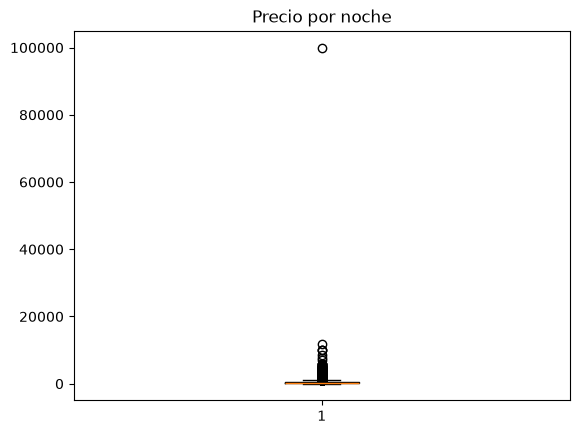

In [79]:
plt.boxplot(df["price"])
plt.title("Precio por noche")
plt.show()

El precio tiene valores muy altos que no son normales. Como está muy cargado a la derecha, usamos el rango intercuartílico (IQR) sobre el logaritmo del precio y quitamos lo que queda por fuera.

In [80]:
log_precio = np.log(df["price"])
q1 = log_precio.quantile(0.25)
q3 = log_precio.quantile(0.75)
iqr = q3 - q1

minimo = np.exp(q1 - 1.5 * iqr)
maximo = np.exp(q3 + 1.5 * iqr)
print("Precio mínimo:", round(minimo, 1))
print("Precio máximo:", round(maximo, 1))

Precio mínimo: 30.0
Precio máximo: 2550.9


In [81]:
df = df[(df["price"] >= minimo) & (df["price"] <= maximo)]
df.shape

(5602, 36)

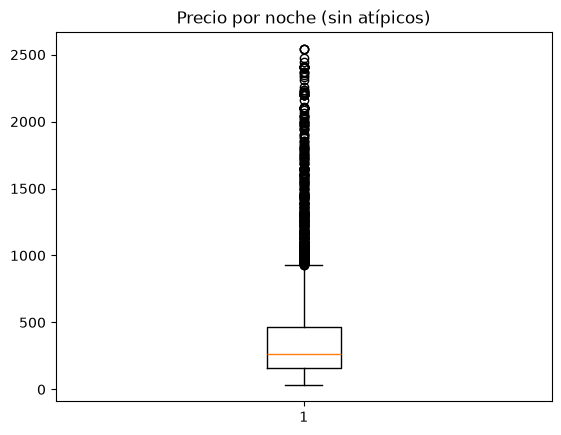

In [82]:
plt.boxplot(df["price"])
plt.title("Precio por noche (sin atípicos)")
plt.show()

Revisamos también si hay anuncios con datos raros, como más habitaciones que huéspedes.

In [83]:
df[df["bedrooms"] > df["accommodates"]][["accommodates", "bedrooms", "beds", "room_type", "price"]]

,accommodates,bedrooms,beds,room_type,price
170,1,3.0,1.0,Private room,67.10
171,1,3.0,1.0,Private room,66.87
928,1,2.0,2.0,Private room,75.32
1288,1,2.0,2.0,Private room,80.00
1994,6,7.0,6.0,Entire home/apt,2018.50
3440,2,4.0,1.0,Private room,117.25
3771,1,2.0,1.0,Private room,66.89
3891,1,3.0,3.0,Private room,71.93
3892,1,3.0,3.0,Private room,82.97
4675,2,3.0,3.0,Entire home/apt,2235.94


Casi todos son habitaciones privadas para pocas personas dentro de casas con varias habitaciones, o propiedades donde el anfitrión limita el número de huéspedes. No son errores, así que **no los eliminamos**.

## 11. Columnas nuevas
- **log_price**: el logaritmo del precio, para el modelo de regresión.
- **long_stay**: 1 si el anuncio pide 30 noches o más.
- **has_reviews**: 1 si el anuncio tiene reseñas (las calificaciones faltan cuando no las tiene).
- **recommended**: 1 si el anuncio tiene al menos 5 reseñas y calificación de 4,9 o más. Con menos de 5 reseñas no tenemos suficiente información para saber si es bueno o no, por eso creamos también **can_evaluate**: los modelos de clasificación se entrenan solo con los anuncios que tienen `can_evaluate = 1`.

In [84]:
df["log_price"] = np.log(df["price"])
df["long_stay"] = (df["minimum_nights"] >= 30).astype(int)
df["has_reviews"] = df["review_scores_rating"].notnull().astype(int)

df["can_evaluate"] = (df["number_of_reviews"] >= 5).astype(int)
df["recommended"] = ((df["can_evaluate"] == 1) & (df["review_scores_rating"] >= 4.9)).astype(int)

df[df["can_evaluate"] == 1]["recommended"].value_counts()

recommended
0    1878
1    1691
Name: count, dtype: int64

**¿Por qué mínimo 5 reseñas y calificación de 4,9?**
- Con pocas reseñas la calificación no es confiable: miramos qué porcentaje de los anuncios con 1 a 4 reseñas tiene un 5,0 perfecto.
- La calificación general resume bien a las demás calificaciones: miramos su correlación con ellas.
- 4,9 es aproximadamente la mediana de la calificación de los anuncios evaluables, así que las dos clases quedan casi del mismo tamaño.

In [85]:
pocas_resenas = df[(df["number_of_reviews"] >= 1) & (df["number_of_reviews"] < 5)]
print("% de anuncios con 1 a 4 reseñas que tienen 5,0:", round((pocas_resenas["review_scores_rating"] == 5).mean() * 100, 1))

evaluables = df[df["can_evaluate"] == 1]
print("Mediana de la calificación en los evaluables:", evaluables["review_scores_rating"].median())
print("% de recomendados entre los evaluables:", round(evaluables["recommended"].mean() * 100, 1))

calificaciones = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
                  "review_scores_checkin", "review_scores_communication", "review_scores_location",
                  "review_scores_value"]
evaluables[calificaciones].corr()["review_scores_rating"].round(2)

% de anuncios con 1 a 4 reseñas que tienen 5,0: 70.1
Mediana de la calificación en los evaluables: 4.89
% de recomendados entre los evaluables: 47.4


review_scores_rating           1.00
review_scores_accuracy         0.87
review_scores_cleanliness      0.78
review_scores_checkin          0.70
review_scores_communication    0.76
review_scores_location         0.50
review_scores_value            0.83
Name: review_scores_rating, dtype: float64

## 12. Datos de entrenamiento y prueba
Separamos de una vez los datos en entrenamiento (80%) y prueba (20%), al azar y con una semilla fija para que siempre salgan los mismos. Así todos los modelos (regresión, clasificación estadística y red neuronal) se evalúan con los mismos anuncios y se pueden comparar.

In [86]:
prueba = df.sample(frac=0.2, random_state=42)
df["split"] = "train"
df.loc[prueba.index, "split"] = "test"
df["split"].value_counts()

split
train    4482
test     1120
Name: count, dtype: int64

## 13. Datos faltantes
Revisamos qué falta todavía.

In [87]:
df.isnull().sum()

id                                0
neighbourhood_cleansed            0
latitude                          0
longitude                         0
property_type                     0
room_type                         0
accommodates                      0
bedrooms                          4
beds                            256
price                             0
minimum_nights                   11
availability_365                  0
number_of_reviews                 0
reviews_per_month              1080
review_scores_rating           1080
review_scores_accuracy         1080
review_scores_cleanliness      1080
review_scores_checkin          1081
review_scores_communication    1080
review_scores_location         1081
review_scores_value            1081
host_is_superhost                 0
host_identity_verified            0
hosts_time_as_host_years          0
host_listings_count               0
estimated_occupancy_l365d         0
estimated_revenue_l365d           0
bathrooms                   

In [88]:
entrenamiento = df[df["split"] == "train"]

for col in calificaciones + ["bedrooms", "beds", "bathrooms", "shared_bath", "minimum_nights"]:
    df[col] = df[col].fillna(entrenamiento[col].median())

df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

df.isnull().sum().sum()

np.int64(0)

## 14. Guardar los datos limpios
Primero guardamos la versión completa con las categorías en texto, para el análisis exploratorio y el tablero.

In [89]:
df.info()

<class 'pandas.DataFrame'>
Index: 5602 entries, 0 to 7404
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           5602 non-null   int64  
 1   neighbourhood_cleansed       5602 non-null   str    
 2   latitude                     5602 non-null   float64
 3   longitude                    5602 non-null   float64
 4   property_type                5602 non-null   str    
 5   room_type                    5602 non-null   str    
 6   accommodates                 5602 non-null   int64  
 7   bedrooms                     5602 non-null   float64
 8   beds                         5602 non-null   float64
 9   price                        5602 non-null   float64
 10  minimum_nights               5602 non-null   float64
 11  availability_365             5602 non-null   int64  
 12  number_of_reviews            5602 non-null   int64  
 13  reviews_per_month            5602 

In [90]:
df.to_csv("datos\listings_limpio.csv", index=False)

<>:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\User\AppData\Local\Temp\ipykernel_20116\2013482424.py:1: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  df.to_csv("datos\listings_limpio.csv", index=False)


Para los modelos, convertimos las variables categóricas en variables dummy y guardamos por separado los datos de entrenamiento y de prueba.

In [91]:
df_modelo = pd.get_dummies(df, columns=["room_type", "property_type", "neighbourhood_cleansed"],
                           drop_first=True, dtype=int)
df_modelo.shape

(5602, 85)

In [92]:
train = df_modelo[df_modelo["split"] == "train"].drop(columns=["split"])
test = df_modelo[df_modelo["split"] == "test"].drop(columns=["split"])

train.to_csv("datos/train.csv", index=False)
test.to_csv("datos/test.csv", index=False)
print("train:", train.shape, "| test:", test.shape)

train: (4482, 84) | test: (1120, 84)


## 15. Resumen

In [93]:
print("Datos originales:", filas_iniciales, "filas x", columnas_iniciales, "columnas")
print("Datos limpios:", df.shape[0], "filas x", df.shape[1], "columnas")
print("Filas conservadas:", round(df.shape[0] / filas_iniciales * 100, 1), "%")
print("Datos faltantes:", df.isnull().sum().sum())
print("train.csv:", train.shape, "| test.csv:", test.shape)

Datos originales: 7405 filas x 90 columnas
Datos limpios: 5602 filas x 42 columnas
Filas conservadas: 75.7 %
Datos faltantes: 0
train.csv: (4482, 84) | test.csv: (1120, 84)
